# 5A. Transfer Learning - Caltech-101 (VGG16)

In [1]:
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = keras.utils.image_dataset_from_directory(
    "../datasets/Object Detection/caltech-101",
    image_size=(128, 128), validation_split=0.2, subset="training", seed=42)
val = keras.utils.image_dataset_from_directory(
    "../datasets/Object Detection/caltech-101",
    image_size=(128, 128), validation_split=0.2, subset="validation", seed=42)

n_classes = len(train.class_names)
print("classes:", n_classes)

train = train.prefetch(2)
val = val.prefetch(2)

Found 9144 files belonging to 102 classes.


Using 7316 files for training.


Found 9144 files belonging to 102 classes.


Using 1828 files for validation.


classes: 102


In [3]:
base = keras.applications.VGG16(include_top=False, input_shape=(128, 128, 3))
base.trainable = False

model = keras.Sequential([
    layers.Input(shape=(128, 128, 3)),
    layers.Rescaling(1./255),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(n_classes, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 102)            │        13,158 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,793,510 (56.43 MB)

 Trainable params: 78,822 (307.90 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [4]:
history = model.fit(train, validation_data=val, epochs=3)

Epoch 1/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 295s 1s/step - accuracy: 0.3435 - loss: 3.1391 - val_accuracy: 0.5071 - val_loss: 2.2613
Epoch 2/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 964s 4s/step - accuracy: 0.5854 - loss: 1.8434 - val_accuracy: 0.6439 - val_loss: 1.5837
Epoch 3/3
229/229 ━━━━━━━━━━━━━━━━━━━━ 1433s 6s/step - accuracy: 0.6838 - loss: 1.3465 - val_accuracy: 0.6909 - val_loss: 1.3196


In [5]:
loss, acc = model.evaluate(val)
print(f"val acc (frozen base): {acc:.4f}")

 1/58 ━━━━━━━━━━━━━━━━━━━━ 59s 1s/step - accuracy: 0.6562 - loss: 1.3515

 2/58 ━━━━━━━━━━━━━━━━━━━━ 57s 1s/step - accuracy: 0.6875 - loss: 1.3013

 3/58 ━━━━━━━━━━━━━━━━━━━━ 55s 1s/step - accuracy: 0.6875 - loss: 1.3076

 4/58 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.6406 - loss: 1.4078

 5/58 ━━━━━━━━━━━━━━━━━━━━ 54s 1s/step - accuracy: 0.6250 - loss: 1.4636

 6/58 ━━━━━━━━━━━━━━━━━━━━ 53s 1s/step - accuracy: 0.6406 - loss: 1.4404

... (50 outputs left out)

57/58 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.6908 - loss: 1.3212

58/58 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6909 - loss: 1.3196

58/58 ━━━━━━━━━━━━━━━━━━━━ 64s 1s/step - accuracy: 0.6909 - loss: 1.3196


val acc (frozen base): 0.6909


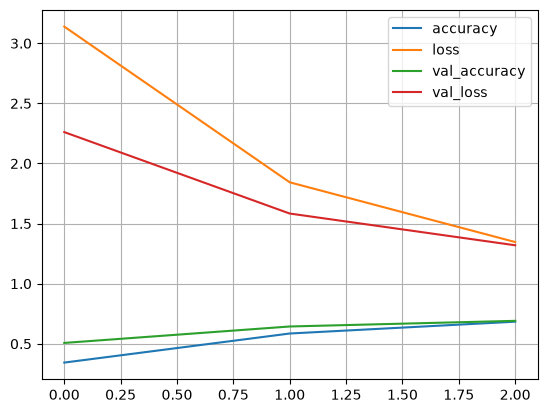

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()